# MRI Preprocessing Pipeline for Shunt Valve Artifact Segmentation

**CRITICAL**: All methods are designed to preserve shunt valve artifacts (signal voids)

## Pipeline Overview:
1. **Normalization** - Standardize intensity values across subjects
2. **Contrast Enhancement** - Improve visibility of structures
3. **N4 Bias Field Correction** - Remove intensity inhomogeneity
4. **Skull Stripping** - Remove non-brain tissue while preserving artifacts

Each step has multiple algorithm options to compare and choose from.

In [ ]:
# Install required packages (uncomment if needed)
!pip install nibabel SimpleITK scikit-image scipy numpy matplotlib antspyx
!pip install antspyx


In [1]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path
import SimpleITK as sitk
from scipy import ndimage
from skimage import exposure, filters, morphology
import warnings
import subprocess
import os
import ants
warnings.filterwarnings('ignore')

## Configuration

In [2]:
# ============================================================================
# CONFIGURATION - UPDATE THESE PATHS
# ============================================================================

# Input file
INPUT_IMAGE = "data/Train/subj010/subj010_image.nii.gz"

#Ground truth mask to verify artifact preservation
GROUND_TRUTH_MASK = "data/Train/subj010/subj010_artifact.nii.gz"  

# Output directory
OUTPUT_DIR = "data/Preprocessed/subj001/"

# Create output directory
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

## Helper Functions

In [3]:
def load_nifti(filepath):
    """Load NIfTI file and return data and image object"""
    img = nib.load(filepath)
    data = img.get_fdata()
    return data, img

def save_nifti(data, reference_img, output_path):
    """Save data as NIfTI using reference image's affine and header"""
    new_img = nib.Nifti1Image(data.astype(np.float32), reference_img.affine, reference_img.header)
    nib.save(new_img, output_path)
    print(f"  ✓ Saved: {output_path}")

def visualize_comparison(original, processed, title, slice_idx=None, mask=None):
    """
    Compare original and processed images
    
    Args:
        original: Original image data
        processed: Processed image data
        title: Title for the plot
        slice_idx: Slice index (if None, use center)
        mask: Optional mask to overlay (e.g., artifact mask)
    """
    if slice_idx is None:
        slice_idx = original.shape[2] // 2
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Original
    axes[0].imshow(original[:, :, slice_idx].T, cmap='gray', origin='lower')
    axes[0].set_title('Original', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    if mask is not None:
        mask_slice = mask[:, :, slice_idx].T
        if mask_slice.max() > 0:
            axes[0].contour(mask_slice, levels=[0.5], colors='red', linewidths=2)
    
    # Processed
    axes[1].imshow(processed[:, :, slice_idx].T, cmap='gray', origin='lower')
    axes[1].set_title('Processed', fontsize=14, fontweight='bold')
    axes[1].axis('off')
    if mask is not None:
        if mask_slice.max() > 0:
            axes[1].contour(mask_slice, levels=[0.5], colors='red', linewidths=2)
    
    # Difference
    diff = np.abs(original - processed)
    axes[2].imshow(diff[:, :, slice_idx].T, cmap='hot', origin='lower')
    axes[2].set_title('Absolute Difference', fontsize=14, fontweight='bold')
    axes[2].axis('off')
    
    plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

def compute_statistics(data, name="Image"):
    """Compute and print statistics for image data"""
    nonzero = data[data > 0]
    if len(nonzero) > 0:
        print(f"\n{name} Statistics:")
        print(f"  Min:    {data.min():.4f}")
        print(f"  Max:    {data.max():.4f}")
        print(f"  Mean:   {nonzero.mean():.4f}")
        print(f"  Std:    {nonzero.std():.4f}")
        print(f"  Median: {np.median(nonzero):.4f}")
        print(f"  P5-P95: [{np.percentile(nonzero, 5):.4f}, {np.percentile(nonzero, 95):.4f}]")

## Load Input Data


✓ Image loaded successfully
  Shape: (192, 224, 192)
  Spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) mm
  Data type: float64

Original Image Statistics:
  Min:    0.0000
  Max:    505.7432
  Mean:   60.4661
  Std:    72.2479
  Median: 11.4016
  P5-P95: [1.9211, 201.3364]

✓ Ground truth mask loaded
  Artifact voxels: 14,425


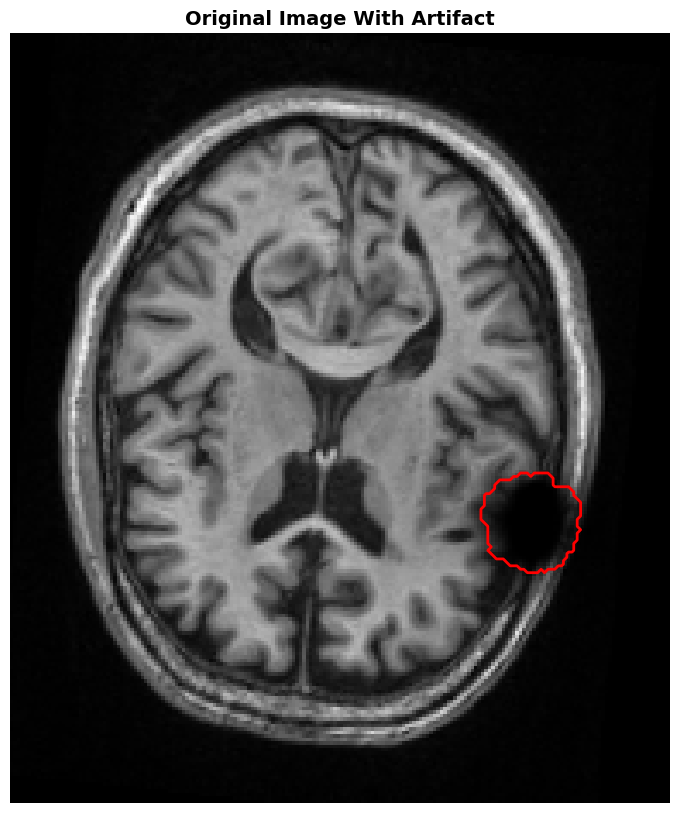

In [4]:
# Load original image
original_data, original_img = load_nifti(INPUT_IMAGE)

print(f"\n✓ Image loaded successfully")
print(f"  Shape: {original_data.shape}")
print(f"  Spacing: {original_img.header.get_zooms()[:3]} mm")
print(f"  Data type: {original_data.dtype}")

compute_statistics(original_data, "Original Image")

# Load ground truth mask if available
gt_mask = None
if GROUND_TRUTH_MASK:
    gt_mask, _ = load_nifti(GROUND_TRUTH_MASK)
    print(f"\n✓ Ground truth mask loaded")
    print(f"  Artifact voxels: {np.sum(gt_mask > 0):,}")

# Visualize original
center_slice = original_data.shape[2] // 2
plt.figure(figsize=(10, 10))
plt.imshow(original_data[:, :, center_slice].T, cmap='gray', origin='lower')
if gt_mask is not None:
    mask_slice = gt_mask[:, :, center_slice].T
    if mask_slice.max() > 0:
        plt.contour(mask_slice, levels=[0.5], colors='red', linewidths=2)
plt.title('Original Image With Artifact', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

---
# 1. INTENSITY NORMALIZATION

Goal: Standardize intensity values across subjects while preserving relative contrasts

## Method 1.1: Z-Score Normalization

Applying Z-Score Normalization...

Z-Score Normalized Statistics:
  Min:    -0.8231
  Max:    6.2935
  Mean:   1.1408
  Std:    0.6789
  Median: 1.0944
  P5-P95: [0.1532, 2.5243]


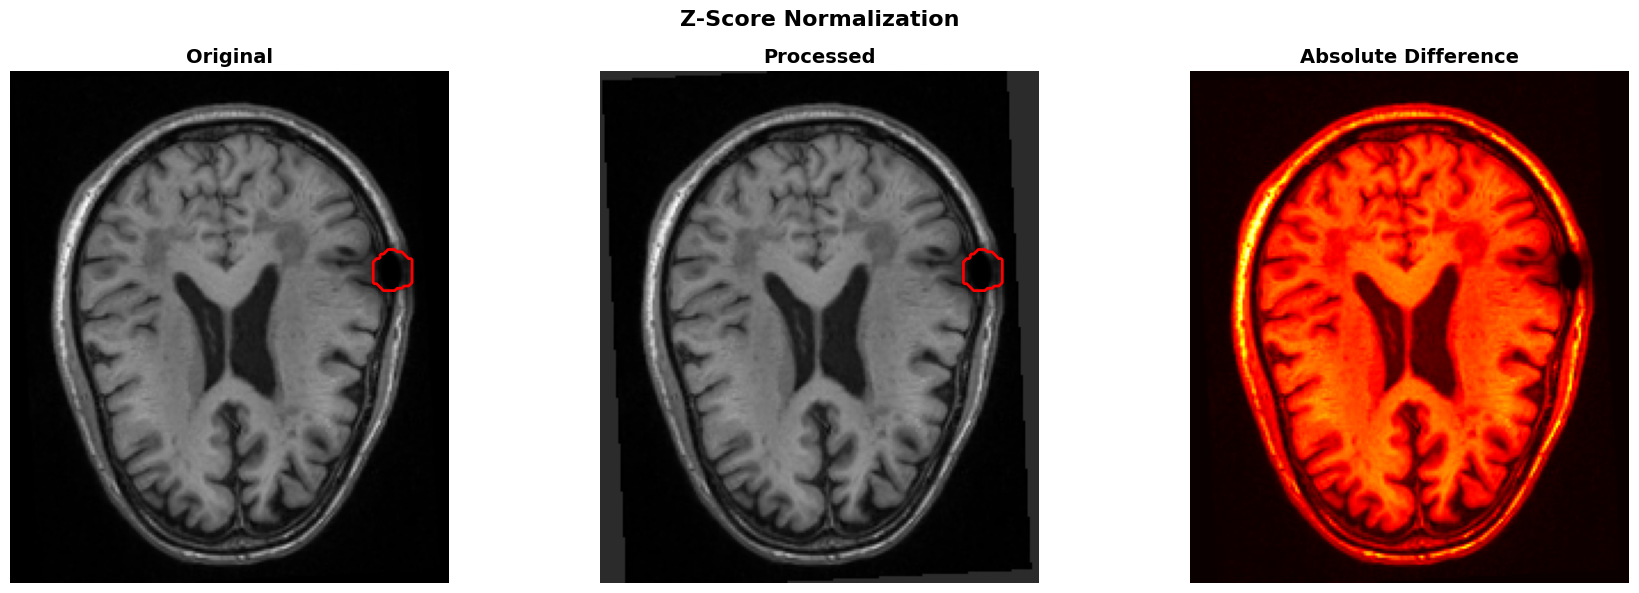

In [7]:
def normalize_zscore(data, mask=None):
    """
    Z-score normalization: (x - mean) / std
    
    Pros: Simple, preserves outliers (artifacts)
    Cons: Sensitive to extreme values
    """
    data = data.copy()
    
    if mask is not None:
        # Only compute stats on masked region (brain)
        brain_voxels = data[mask > 0]
    else:
        # Use all non-zero voxels
        brain_voxels = data[data > 0]
    
    if len(brain_voxels) == 0:
        return data
    
    mean = brain_voxels.mean()
    std = brain_voxels.std()
    
    # Normalize
    data[data > 0] = (data[data > 0] - mean) / (std + 1e-8)
    
    return data

print("Applying Z-Score Normalization...")
normalized_zscore = normalize_zscore(original_data)
compute_statistics(normalized_zscore, "Z-Score Normalized")

visualize_comparison(original_data, normalized_zscore, 
                    "Z-Score Normalization", mask=gt_mask)

## Method 1.2: Min-Max Normalization

Applying Min-Max Normalization...

Min-Max Normalized Statistics:
  Min:    0.0000
  Max:    1.0000
  Mean:   0.2182
  Std:    0.2657
  Median: 0.0301
  P5-P95: [0.0030, 0.6876]


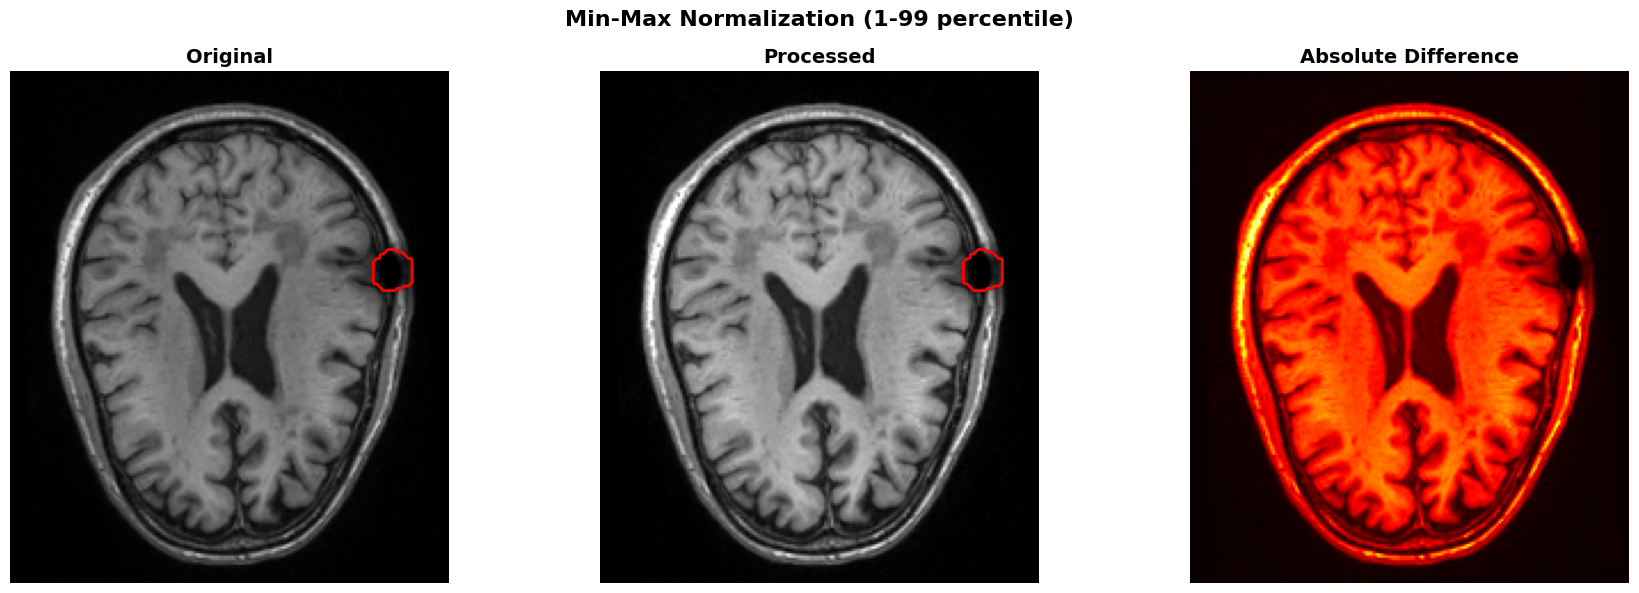

  ✓ Saved: data/Preprocessed/subj001/normalized_minmax.nii.gz


In [8]:
def normalize_minmax(data, percentile_range=(1, 99)):
    """
    Min-Max normalization to [0, 1] range
    
    Args:
        percentile_range: Use percentiles instead of absolute min/max for robustness
    
    Pros: Fixed output range, robust to outliers with percentiles
    Cons: Can compress dynamic range
    """
    data = data.copy()
    nonzero = data[data > 0]
    
    if len(nonzero) == 0:
        return data
    
    # Use percentiles for robustness
    vmin = np.percentile(nonzero, percentile_range[0])
    vmax = np.percentile(nonzero, percentile_range[1])
    
    # Normalize
    data[data > 0] = np.clip((data[data > 0] - vmin) / (vmax - vmin + 1e-8), 0, 1)
    
    return data

# Apply min-max normalization
print("Applying Min-Max Normalization...")
normalized_minmax = normalize_minmax(original_data)
compute_statistics(normalized_minmax, "Min-Max Normalized")

# Visualize
visualize_comparison(original_data, normalized_minmax, 
                    "Min-Max Normalization (1-99 percentile)", mask=gt_mask)

# Save
save_nifti(normalized_minmax, original_img, 
          Path(OUTPUT_DIR) / "normalized_minmax.nii.gz")

## Method 1.3: White Matter Normalization

Applying White Matter Normalization...

White Matter Normalized Statistics:
  Min:    0.0000
  Max:    2.7623
  Mean:   0.3195
  Std:    0.3881
  Median: 0.0461
  P5-P95: [0.0090, 1.0000]


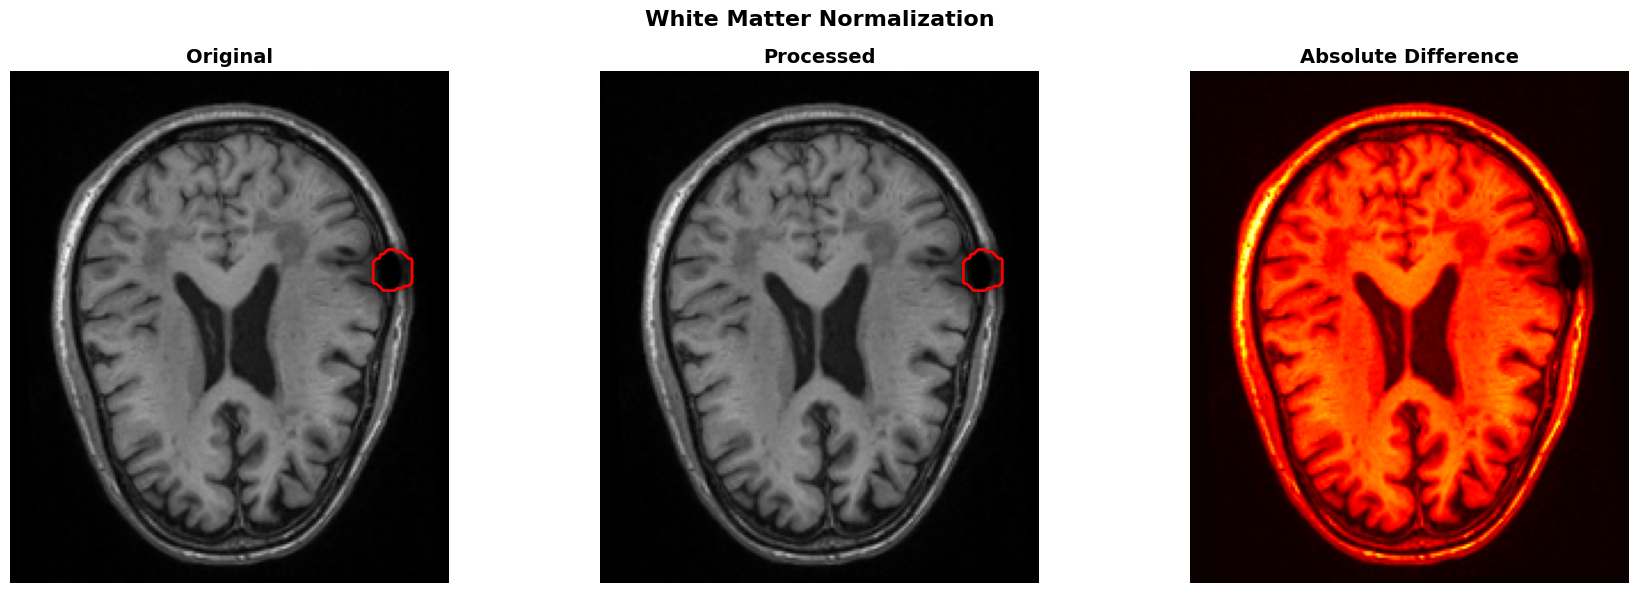

  ✓ Saved: data/Preprocessed/subj001/normalized_wm.nii.gz


In [9]:
def normalize_white_matter(data, wm_percentile=95):
    """
    Normalize by white matter peak intensity
    
    Assumes white matter is the bright peak in T1-weighted images
    
    Pros: Anatomically meaningful, consistent across subjects
    Cons: Assumes T1-weighted, may not work for all sequences
    """
    data = data.copy()
    nonzero = data[data > 0]
    
    if len(nonzero) == 0:
        return data
    
    # Estimate white matter intensity (high percentile)
    wm_intensity = np.percentile(nonzero, wm_percentile)
    
    # Normalize so white matter has value ~1
    data = data / (wm_intensity + 1e-8)
    
    return data

# Apply white matter normalization
print("Applying White Matter Normalization...")
normalized_wm = normalize_white_matter(original_data)
compute_statistics(normalized_wm, "White Matter Normalized")

# Visualize
visualize_comparison(original_data, normalized_wm, 
                    "White Matter Normalization", mask=gt_mask)

# Save
save_nifti(normalized_wm, original_img, 
          Path(OUTPUT_DIR) / "normalized_wm.nii.gz")

## Method 1.4: Histogram Matching

Applying Histogram Matching...

Histogram Matched Statistics:
  Min:    91.8698
  Max:    255.0000
  Mean:   129.6666
  Std:    27.0946
  Median: 128.0043
  P5-P95: [91.8698, 177.3663]


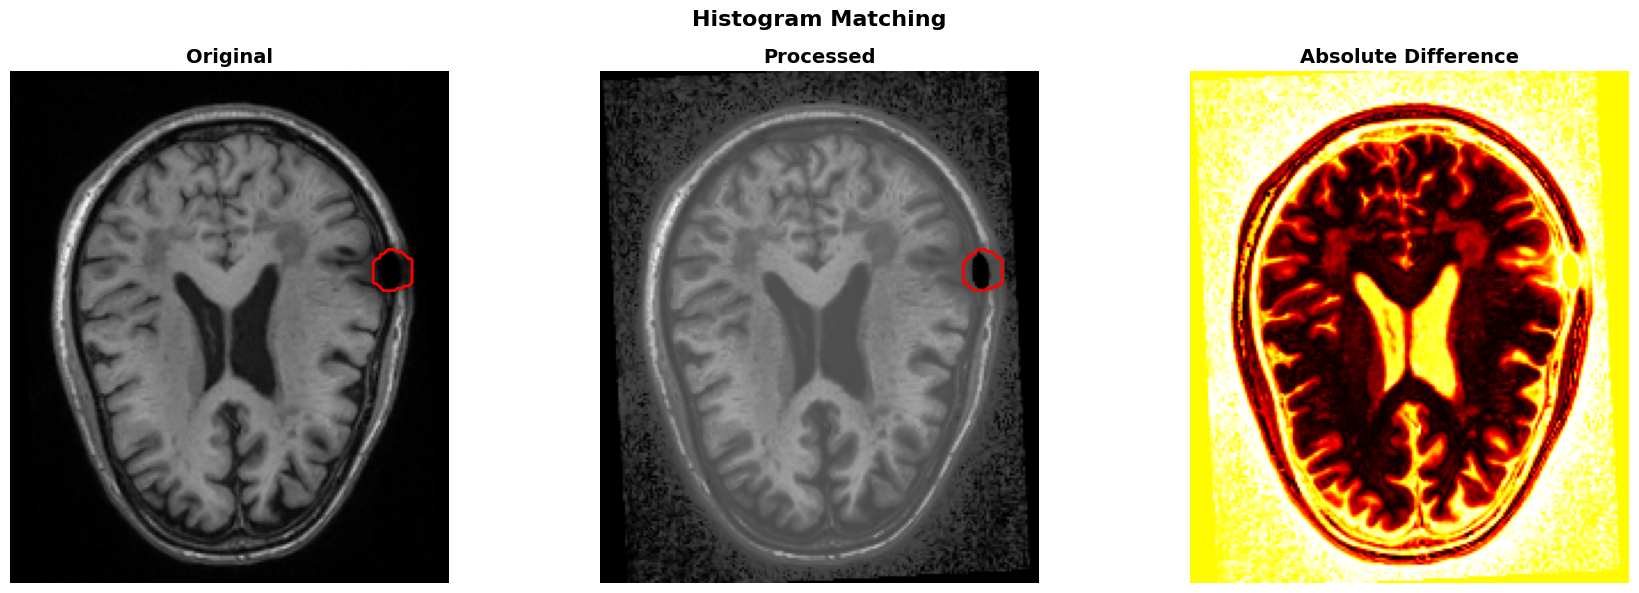

  ✓ Saved: data/Preprocessed/subj001/normalized_histogram.nii.gz


In [10]:
def normalize_histogram_matching(source_data, reference_data=None, n_bins=256):
    """
    Match histogram to a reference image
    
    If no reference provided, matches to a standard histogram shape
    
    Pros: Preserves relationships, consistent appearance
    Cons: Needs reference image
    """
    from skimage.exposure import match_histograms
    
    if reference_data is None:
        # Create synthetic reference with normal distribution
        reference_data = np.random.normal(128, 30, source_data.shape)
        reference_data = np.clip(reference_data, 0, 255)
    
    # Match histograms
    matched = match_histograms(source_data, reference_data)
    
    return matched

# Apply histogram matching
print("Applying Histogram Matching...")
normalized_hist = normalize_histogram_matching(original_data)
compute_statistics(normalized_hist, "Histogram Matched")

# Visualize
visualize_comparison(original_data, normalized_hist, 
                    "Histogram Matching", mask=gt_mask)

# Save
save_nifti(normalized_hist, original_img, 
          Path(OUTPUT_DIR) / "normalized_histogram.nii.gz")

---
# 2. CONTRAST ENHANCEMENT

Goal: Improve visibility of structures and artifacts

## Method 2.1: Histogram Equalization

Applying Adaptive Histogram Equalization (CLAHE)...

CLAHE Enhanced Statistics:
  Min:    0.0000
  Max:    269.8777
  Mean:   94.3550
  Std:    79.6987
  Median: 62.3897
  P5-P95: [8.7081, 246.5980]


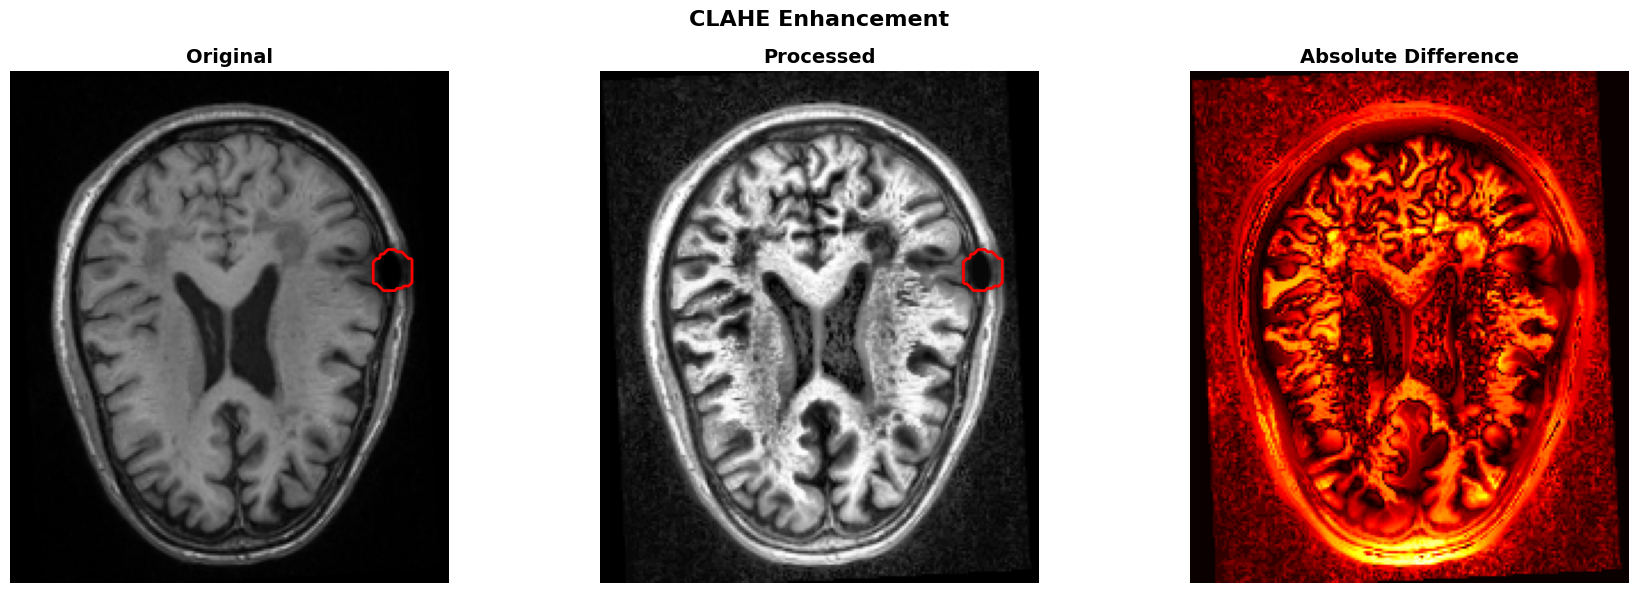

In [11]:
def enhance_histogram_equalization(data, clip_limit=0.03):
    """
    Adaptive Histogram Equalization (CLAHE)
    
    Pros: Enhances local contrast, reveals hidden details
    Cons: Can amplify noise
    """
    from skimage import exposure
    
    data = data.copy()
    
    # Normalize to [0, 1] for CLAHE
    nonzero = data[data > 0]
    if len(nonzero) == 0:
        return data
    
    vmin, vmax = np.percentile(nonzero, [1, 99])
    data_norm = np.clip((data - vmin) / (vmax - vmin + 1e-8), 0, 1)
    
    # Apply CLAHE slice by slice (3D CLAHE is computationally expensive)
    enhanced = np.zeros_like(data_norm)
    for i in range(data.shape[2]):
        if data_norm[:, :, i].max() > 0:
            enhanced[:, :, i] = exposure.equalize_adapthist(
                data_norm[:, :, i], 
                clip_limit=clip_limit
            )
    
    # Scale back to original range
    enhanced = enhanced * (vmax - vmin) + vmin
    enhanced[data == 0] = 0
    
    return enhanced

# Apply histogram equalization
print("Applying Adaptive Histogram Equalization (CLAHE)...")
enhanced_clahe = enhance_histogram_equalization(original_data)
compute_statistics(enhanced_clahe, "CLAHE Enhanced")

# Visualize
visualize_comparison(original_data, enhanced_clahe, 
                    "CLAHE Enhancement", mask=gt_mask)

## Method 2.2: Gamma Correction

Applying Gamma Correction with different values...

Gamma=0.8 Statistics:
  Min:    0.0000
  Max:    512.5097
  Mean:   79.9473
  Std:    86.8237
  Median: 19.3962
  P5-P95: [5.2678, 227.3452]


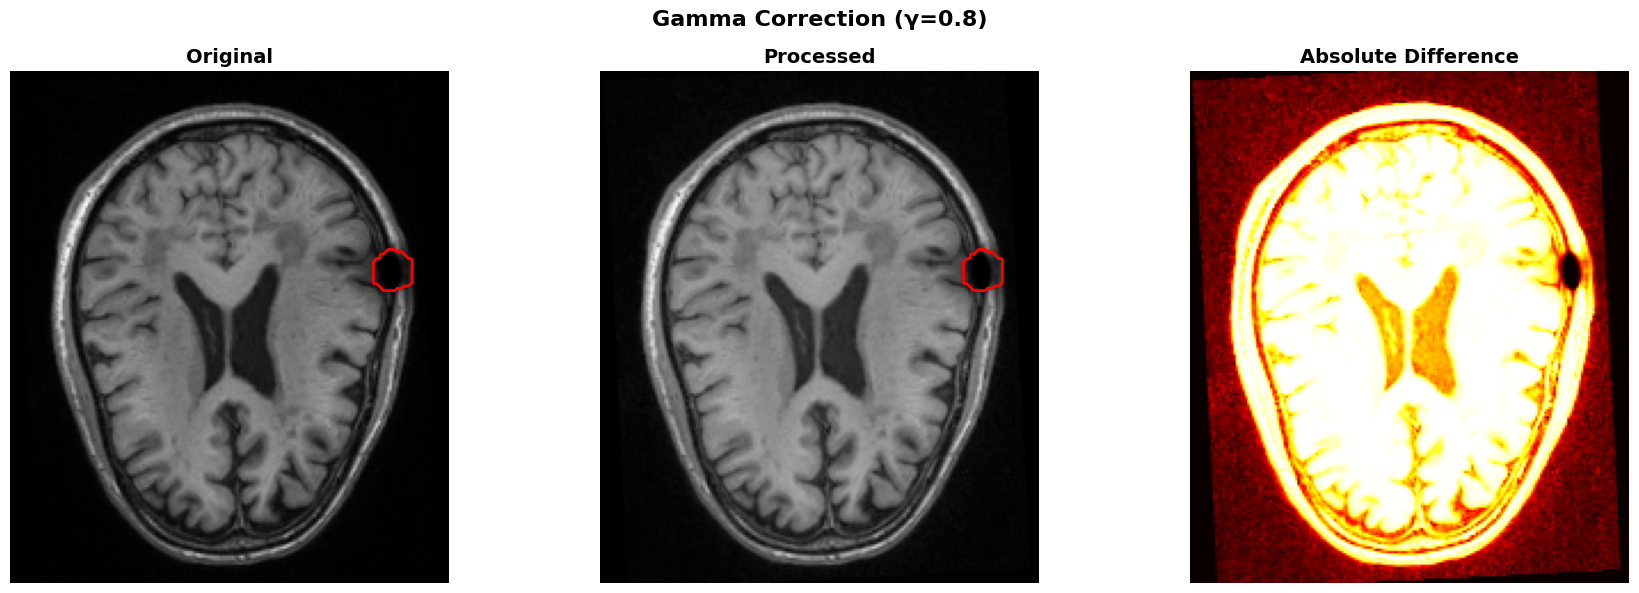


Gamma=1.5 Statistics:
  Min:    0.0000
  Max:    512.5097
  Mean:   30.7188
  Std:    44.8561
  Median: 1.1053
  P5-P95: [0.0960, 111.6340]


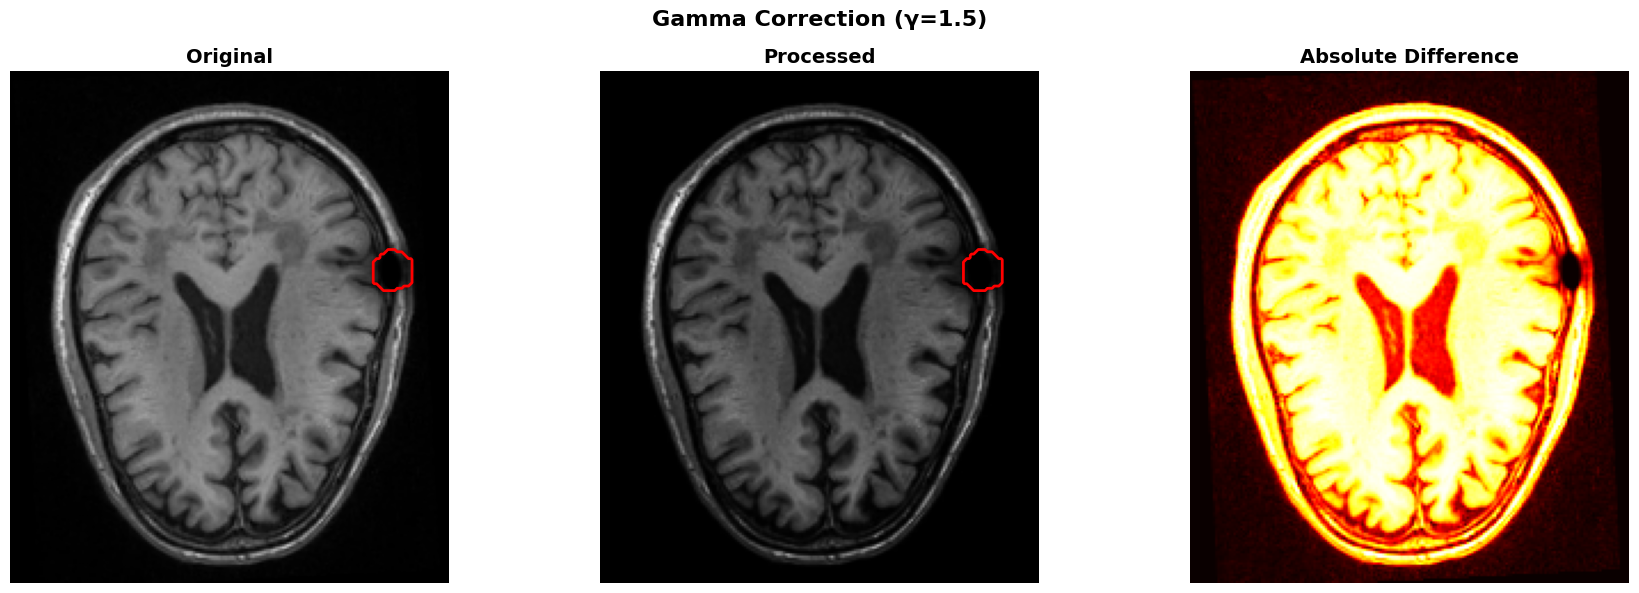


Gamma=2.0 Statistics:
  Min:    0.0000
  Max:    512.5097
  Mean:   16.9758
  Std:    28.8688
  Median: 0.1428
  P5-P95: [0.0055, 67.1678]


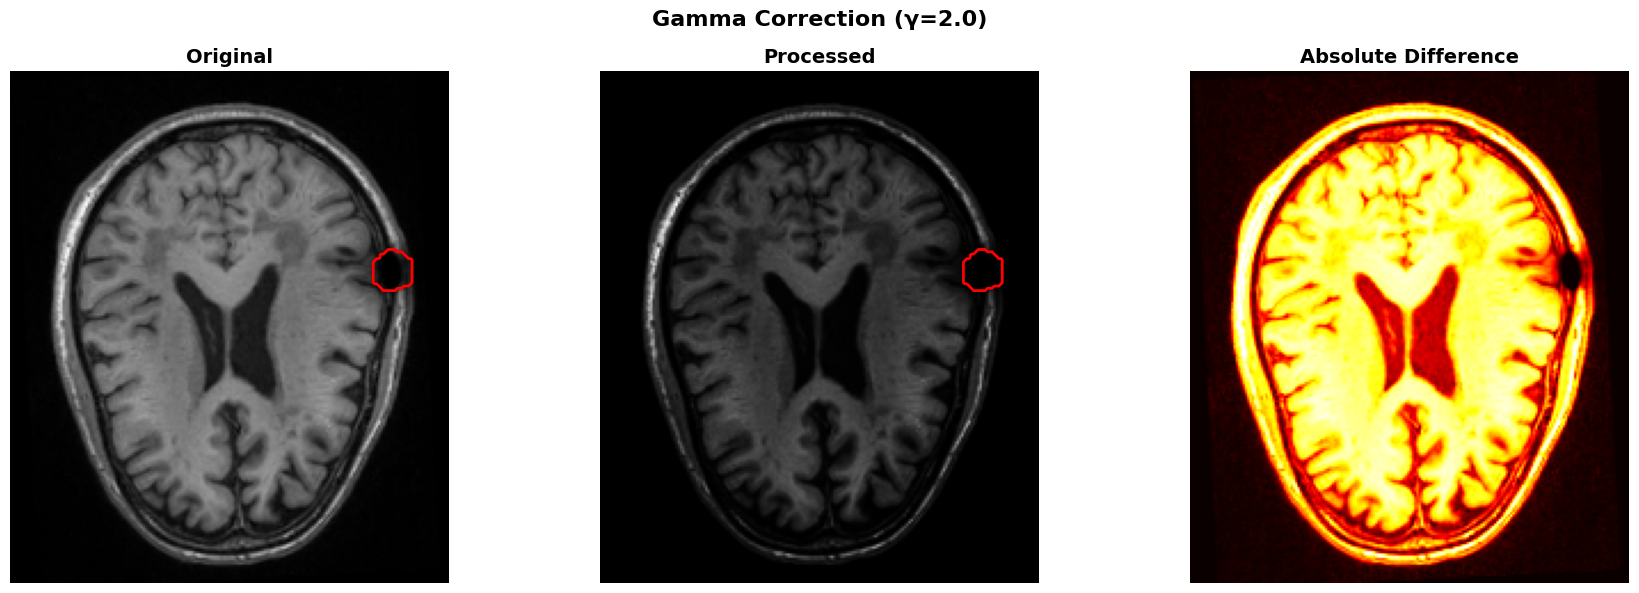

In [12]:
def enhance_gamma_correction(data, gamma=1.5):
    """
    Gamma correction: output = input^gamma
    
    Args:
        gamma: < 1 brightens dark regions, > 1 darkens bright regions
    
    Pros: Simple, fast, preserves relationships
    Cons: Global operation, not adaptive
    """
    data = data.copy()
    
    # Normalize to [0, 1]
    nonzero = data[data > 0]
    if len(nonzero) == 0:
        return data
    
    vmin, vmax = nonzero.min(), nonzero.max()
    data_norm = (data - vmin) / (vmax - vmin + 1e-8)
    
    # Apply gamma
    enhanced = np.power(data_norm, gamma)
    
    # Scale back
    enhanced = enhanced * (vmax - vmin) + vmin
    enhanced[data == 0] = 0
    
    return enhanced

# Try different gamma values
gamma_values = [0.8, 1.5, 2.0]

print("Applying Gamma Correction with different values...")

for gamma in gamma_values:
    enhanced_gamma = enhance_gamma_correction(original_data, gamma=gamma)
    compute_statistics(enhanced_gamma, f"Gamma={gamma}")
    
    # Visualize
    visualize_comparison(original_data, enhanced_gamma, 
                        f"Gamma Correction (γ={gamma})", mask=gt_mask)

## Method 2.3: Unsharp Masking

Applying Unsharp Masking...

Unsharp Masked Statistics:
  Min:    0.0000
  Max:    768.7646
  Mean:   72.0665
  Std:    92.2599
  Median: 8.8858
  P5-P95: [0.8686, 238.9783]


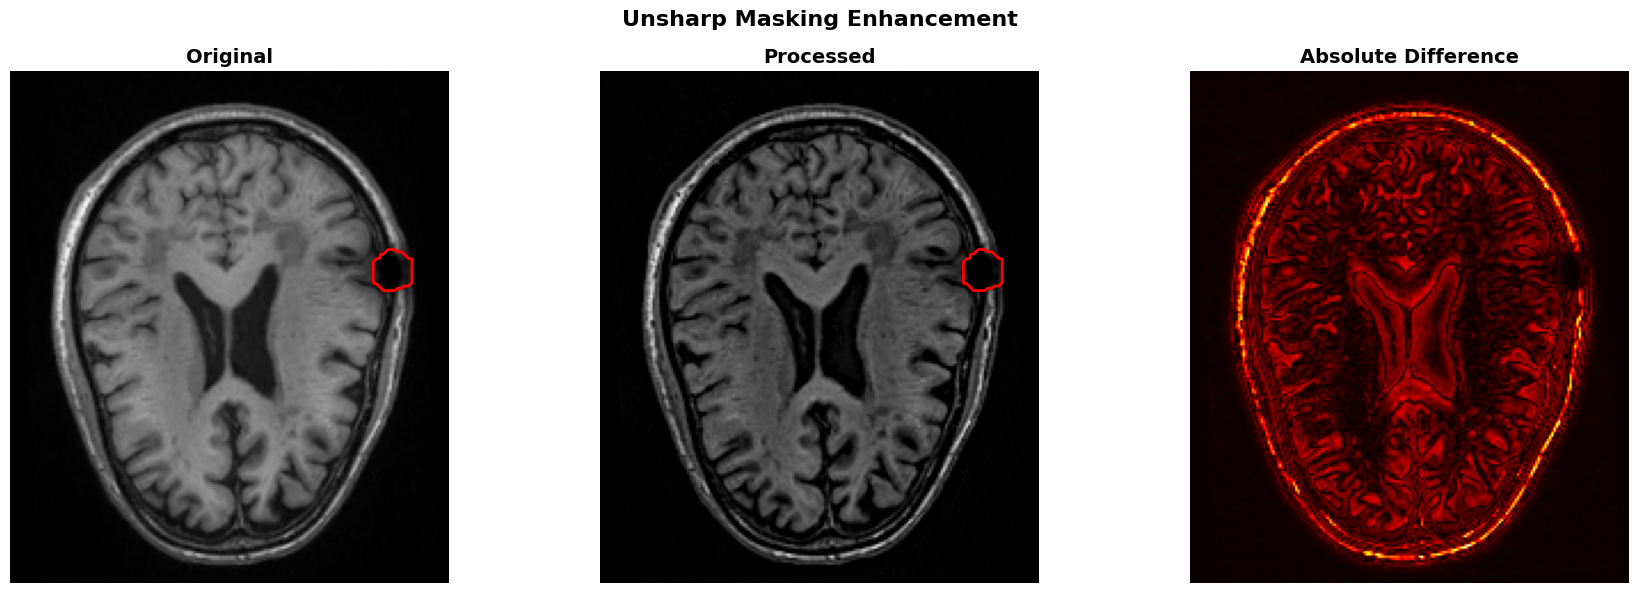

In [13]:
def enhance_unsharp_mask(data, radius=2.0, amount=1.0):
    """
    Unsharp masking: enhances edges and fine details
    
    Args:
        radius: Gaussian blur radius
        amount: Strength of enhancement
    
    Pros: Enhances edges and artifacts, preserves signal voids
    Cons: Can amplify noise
    """
    from scipy.ndimage import gaussian_filter
    
    data = data.copy()
    
    # Create blurred version
    blurred = gaussian_filter(data, sigma=radius)
    
    # Unsharp mask: original + amount * (original - blurred)
    enhanced = data + amount * (data - blurred)
    
    # Clip to reasonable range
    enhanced = np.clip(enhanced, data.min(), data.max() * 1.5)
    
    return enhanced

# Apply unsharp masking
print("Applying Unsharp Masking...")
enhanced_unsharp = enhance_unsharp_mask(original_data, radius=2.0, amount=1.5)
compute_statistics(enhanced_unsharp, "Unsharp Masked")

# Visualize
visualize_comparison(original_data, enhanced_unsharp, 
                    "Unsharp Masking Enhancement", mask=gt_mask)

---
# 3. N4 BIAS FIELD CORRECTION

Goal: Remove intensity inhomogeneity caused by magnetic field variations

**CRITICAL**: Preserves artifacts as they are real signal voids, not bias

## Method 3.1: N4ITK Bias Correction (SimpleITK)

Applying N4ITK Bias Field Correction...
  Running N4ITK bias correction (this may take 2-5 minutes)...
  ✓ N4ITK correction complete

N4 Corrected Statistics:
  Min:    0.0000
  Max:    516.4624
  Mean:   57.3632
  Std:    68.5597
  Median: 8.7827
  P5-P95: [1.7446, 175.7211]


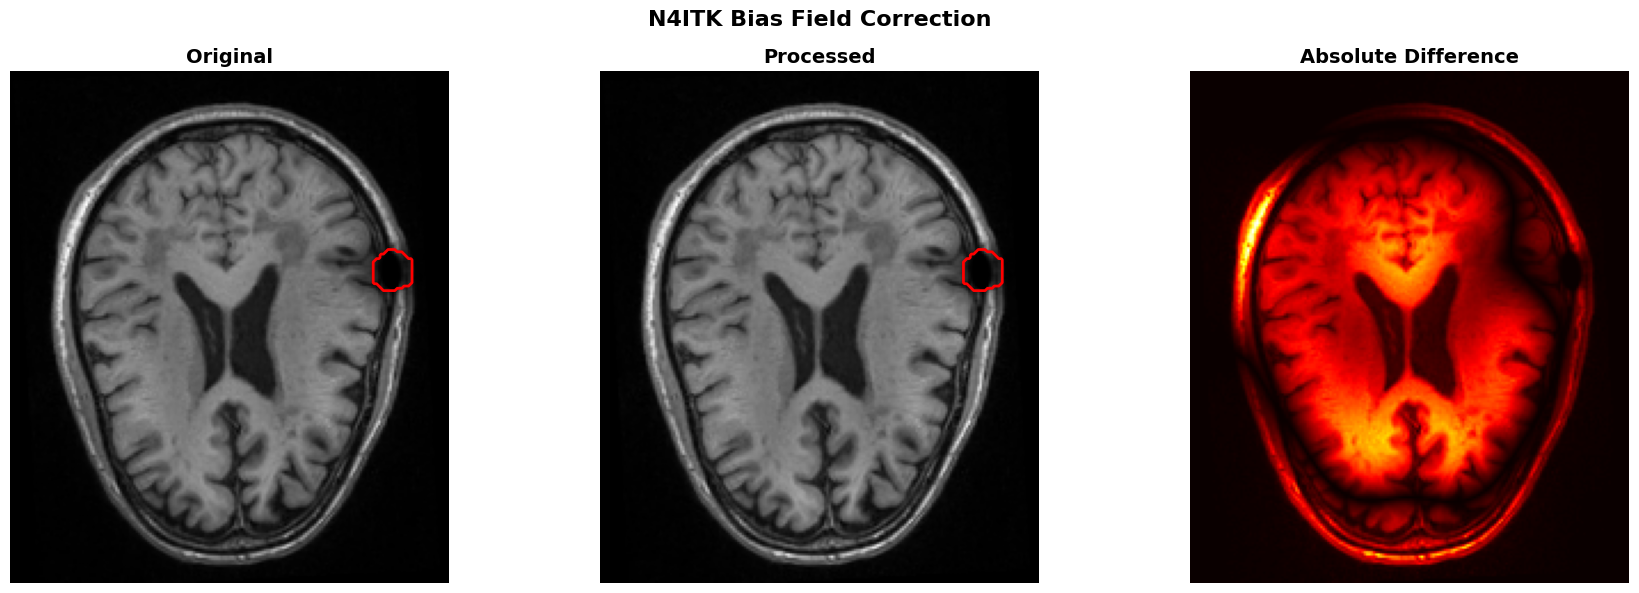

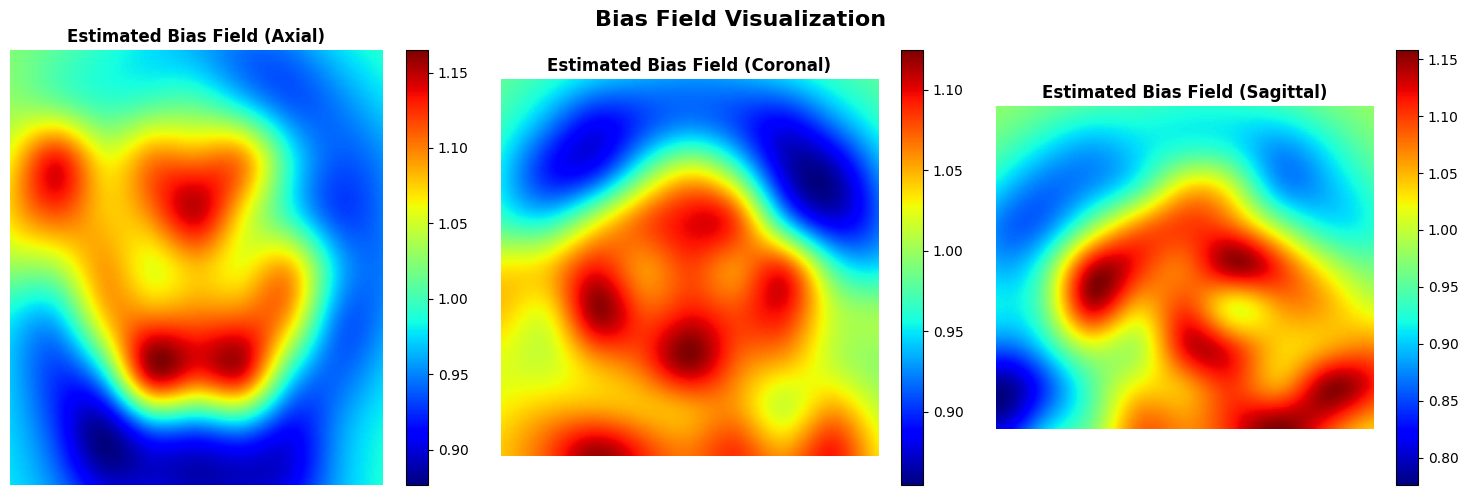

In [14]:
def bias_correction_n4itk(data, reference_img, mask=None, shrink_factor=4, n_iterations=[50, 50, 50, 50]):
    """
    N4ITK bias field correction using SimpleITK
    
    Args:
        shrink_factor: Downsample factor for speed (4 = 4x faster)
        n_iterations: Iterations per level
    
    Pros: Gold standard, preserves artifacts
    Cons: Slow, requires SimpleITK
    """
    print("  Running N4ITK bias correction (this may take 2-5 minutes)...")
    
    # Convert to SimpleITK image
    sitk_image = sitk.GetImageFromArray(data.transpose(2, 1, 0))
    spacing = reference_img.header.get_zooms()[:3]
    spacing = tuple(float(s) for s in spacing)  # Convert to proper format
    sitk_image.SetSpacing(spacing)
    
    # Create mask if not provided
    if mask is None:
        # Simple Otsu thresholding for brain mask
        sitk_mask = sitk.OtsuThreshold(sitk_image, 0, 1)
    else:
        sitk_mask = sitk.GetImageFromArray(mask.transpose(2, 1, 0).astype(np.uint8))
        sitk_mask.SetSpacing(reference_img.header.get_zooms()[:3])
    
    # Cast to float
    sitk_image = sitk.Cast(sitk_image, sitk.sitkFloat32)
    
    # Setup N4 corrector
    corrector = sitk.N4BiasFieldCorrectionImageFilter()
    corrector.SetMaximumNumberOfIterations(n_iterations)
    corrector.SetConvergenceThreshold(0.001)
    
    # Run correction
    corrected_image = corrector.Execute(sitk_image, sitk_mask)
    
    # Get bias field
    log_bias_field = corrector.GetLogBiasFieldAsImage(sitk_image)
    
    # Convert back to numpy
    corrected = sitk.GetArrayFromImage(corrected_image).transpose(2, 1, 0)
    bias_field = sitk.GetArrayFromImage(log_bias_field).transpose(2, 1, 0)
    
    print("  ✓ N4ITK correction complete")
    
    return corrected, np.exp(bias_field)

# Apply N4 bias correction
print("Applying N4ITK Bias Field Correction...")
corrected_n4, bias_field = bias_correction_n4itk(original_data, original_img)
compute_statistics(corrected_n4, "N4 Corrected")

# Visualize
visualize_comparison(original_data, corrected_n4, 
                    "N4ITK Bias Field Correction", mask=gt_mask)

# Visualize bias field
plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(bias_field[:, :, center_slice].T, cmap='jet', origin='lower')
plt.colorbar()
plt.title('Estimated Bias Field (Axial)', fontweight='bold')
plt.axis('off')

plt.subplot(132)
plt.imshow(bias_field[:, bias_field.shape[1]//2, :].T, cmap='jet', origin='lower')
plt.colorbar()
plt.title('Estimated Bias Field (Coronal)', fontweight='bold')
plt.axis('off')

plt.subplot(133)
plt.imshow(bias_field[bias_field.shape[0]//2, :, :].T, cmap='jet', origin='lower')
plt.colorbar()
plt.title('Estimated Bias Field (Sagittal)', fontweight='bold')
plt.axis('off')

plt.suptitle('Bias Field Visualization', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Method 3.2: Homomorphic Filtering (Fast Alternative)

Applying Homomorphic Filtering...

Homomorphic Corrected Statistics:
  Min:    0.0000
  Max:    362.5087
  Mean:   46.7726
  Std:    44.8265
  Median: 30.5012
  P5-P95: [5.2206, 132.1346]


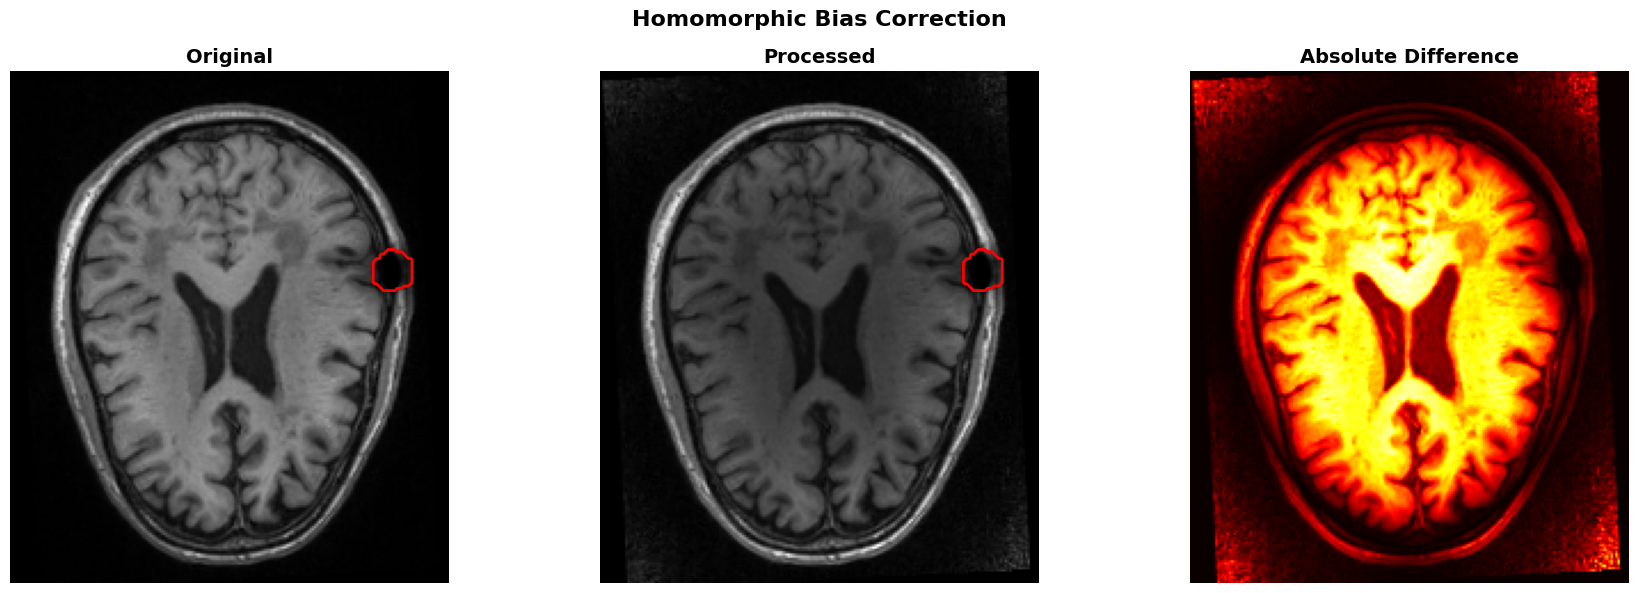

  ✓ Saved: data/Preprocessed/subj001/bias_corrected_homomorphic.nii.gz


In [ ]:
def bias_correction_homomorphic(data, sigma=20):
    """
    Homomorphic filtering for bias correction
    
    Fast approximation using Gaussian filtering
    
    Args:
        sigma: Gaussian smoothing sigma (larger = smoother bias estimate)
    
    Pros: Very fast, no external dependencies
    Cons: Less accurate than N4ITK
    """
    from scipy.ndimage import gaussian_filter
    
    data = data.copy()
    
    # Estimate bias field using heavy smoothing
    # Idea: smooth version approximates multiplicative bias
    smoothed = gaussian_filter(data.astype(float), sigma=sigma)
    
    # Avoid division by zero
    smoothed[smoothed == 0] = 1
    
    # Correct by dividing
    corrected = data / smoothed
    
    # Rescale to original range
    corrected = corrected * data[data > 0].mean()
    corrected[data == 0] = 0
    
    return corrected, smoothed

# Apply homomorphic filtering
print("Applying Homomorphic Filtering...")
corrected_homo, bias_homo = bias_correction_homomorphic(original_data, sigma=20)
compute_statistics(corrected_homo, "Homomorphic Corrected")

# Visualize
visualize_comparison(original_data, corrected_homo, 
                    "Homomorphic Bias Correction", mask=gt_mask)

---
# 4. SKULL STRIPPING

Goal: Remove non-brain tissue while PRESERVING shunt valve artifacts

**CRITICAL**: Shunt valves are often in ventricles - must not be removed!

## Method 4.1: Otsu Thresholding + Morphology (Conservative)

In [ ]:
def skull_strip_otsu(data, closing_radius=3, opening_radius=2):
    """
    Simple Otsu thresholding with morphological operations
    
    CONSERVATIVE: Keeps more tissue to preserve artifacts
    
    Pros: Fast, simple, preserves internal structures
    Cons: May keep some skull, less clean than advanced methods
    """
    from skimage.filters import threshold_otsu
    from skimage.morphology import binary_closing, binary_opening, ball
    from scipy.ndimage import binary_fill_holes
    
    data = data.copy()
    
    # Threshold
    nonzero = data[data > 0]
    threshold = threshold_otsu(nonzero)
    mask = data > threshold * 0.3  # Use lower threshold to keep more
    
    # Morphological closing to connect components
    mask = binary_closing(mask, ball(closing_radius))
    
    # Fill holes (important for ventricles with artifacts)
    mask = binary_fill_holes(mask)
    
    # Small opening to remove tiny noise
    mask = binary_opening(mask, ball(opening_radius))
    
    # Keep largest connected component
    from skimage.measure import label
    labeled = label(mask)
    if labeled.max() > 0:
        largest_cc = (labeled == np.argmax(np.bincount(labeled.flat)[1:]) + 1)
        mask = largest_cc
    
    # Apply mask
    stripped = data * mask
    
    return stripped, mask.astype(np.uint8)

# Apply Otsu skull stripping
print("Applying Otsu-based Skull Stripping...")
stripped_otsu, mask_otsu = skull_strip_otsu(original_data)
compute_statistics(stripped_otsu, "Otsu Stripped")

print(f"\nMask Statistics:")
print(f"  Brain voxels: {np.sum(mask_otsu):,}")
print(f"  Percentage kept: {100 * np.sum(mask_otsu) / mask_otsu.size:.2f}%")

# Check artifact preservation if GT available
if gt_mask is not None:
    artifact_preserved = np.sum((gt_mask > 0) & (mask_otsu > 0))
    artifact_total = np.sum(gt_mask > 0)
    print(f"  Artifact preservation: {100 * artifact_preserved / artifact_total:.1f}%")

# Visualize
visualize_comparison(original_data, stripped_otsu, 
                    "Otsu Skull Stripping", mask=gt_mask)

# Show mask
plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(mask_otsu[:, :, center_slice].T, cmap='gray', origin='lower')
plt.title('Brain Mask - Axial', fontweight='bold')
plt.axis('off')

plt.subplot(132)
plt.imshow(original_data[:, :, center_slice].T, cmap='gray', origin='lower')
plt.contour(mask_otsu[:, :, center_slice].T, levels=[0.5], colors='red', linewidths=2)
plt.title('Original + Mask Overlay', fontweight='bold')
plt.axis('off')

plt.subplot(133)
plt.imshow(stripped_otsu[:, :, center_slice].T, cmap='gray', origin='lower')
plt.title('Skull Stripped', fontweight='bold')
plt.axis('off')

plt.suptitle('Otsu Skull Stripping Result', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Method 4.2: Multi-Otsu Thresholding

In [ ]:
def skull_strip_multi_otsu(data, n_classes=3):
    """
    Multi-level Otsu thresholding
    
    Separates background, skull, and brain based on intensity
    
    Pros: Better tissue separation than single Otsu
    Cons: Still intensity-based, may struggle with inhomogeneity
    """
    from skimage.filters import threshold_multiotsu
    from skimage.morphology import binary_closing, binary_opening, ball, remove_small_holes
    from scipy.ndimage import binary_fill_holes
    
    data = data.copy()
    nonzero = data[data > 0]
    
    # Multi-Otsu thresholding
    thresholds = threshold_multiotsu(nonzero, classes=n_classes)
    
    # Keep middle and high intensity regions (brain)
    mask = data > thresholds[0]
    
    # Morphological operations
    mask = binary_closing(mask, ball(3))
    mask = binary_fill_holes(mask)
    mask = remove_small_holes(mask, area_threshold=1000)
    
    # Keep largest component
    from skimage.measure import label
    labeled = label(mask)
    if labeled.max() > 0:
        largest_cc = (labeled == np.argmax(np.bincount(labeled.flat)[1:]) + 1)
        mask = largest_cc
    
    # Apply mask
    stripped = data * mask
    
    return stripped, mask.astype(np.uint8)

# Apply Multi-Otsu skull stripping
print("Applying Multi-Otsu Skull Stripping...")
stripped_multi, mask_multi = skull_strip_multi_otsu(original_data)
compute_statistics(stripped_multi, "Multi-Otsu Stripped")

# Check artifact preservation
if gt_mask is not None:
    artifact_preserved = np.sum((gt_mask > 0) & (mask_multi > 0))
    artifact_total = np.sum(gt_mask > 0)
    print(f"  Artifact preservation: {100 * artifact_preserved / artifact_total:.1f}%")

# Visualize
visualize_comparison(original_data, stripped_multi, 
                    "Multi-Otsu Skull Stripping", mask=gt_mask)

## Method 4.3: Morphological Watershed

In [ ]:
def skull_strip_watershed(data):
    """
    Watershed-based skull stripping
    
    Uses gradient and markers to segment brain
    
    Pros: Can handle complex boundaries
    Cons: Sensitive to parameters, slower
    """
    from skimage.filters import threshold_otsu
    from skimage.morphology import ball, binary_erosion, binary_dilation
    from scipy.ndimage import distance_transform_edt, gaussian_filter
    from skimage.measure import label
    from skimage.segmentation import watershed
    
    data = data.copy()
    
    # Initial threshold
    nonzero = data[data > 0]
    threshold = threshold_otsu(nonzero)
    binary = data > threshold * 0.4
    
    # Compute gradient
    gradient = gaussian_filter(data, sigma=1)
    gradient = np.gradient(gradient)
    gradient = np.sqrt(sum([g**2 for g in gradient]))
    
    # Create markers
    # Sure brain: eroded binary mask
    sure_brain = binary_erosion(binary, ball(5))
    
    # Sure background: dilated inverse
    sure_bg = binary_dilation(~binary, ball(3))
    
    # Unknown region
    unknown = binary & ~sure_brain & ~sure_bg
    
    # Label markers
    markers = np.zeros_like(data, dtype=int)
    markers[sure_bg] = 1
    markers[sure_brain] = 2
    
    # Watershed
    labels = watershed(gradient, markers, mask=binary)
    
    # Brain is label 2
    mask = (labels == 2)
    
    # Clean up
    from scipy.ndimage import binary_fill_holes
    mask = binary_fill_holes(mask)
    
    # Apply
    stripped = data * mask
    
    return stripped, mask.astype(np.uint8)

# Apply watershed skull stripping
print("Applying Watershed Skull Stripping...")
stripped_watershed, mask_watershed = skull_strip_watershed(original_data)
compute_statistics(stripped_watershed, "Watershed Stripped")

# Check artifact preservation
if gt_mask is not None:
    artifact_preserved = np.sum((gt_mask > 0) & (mask_watershed > 0))
    artifact_total = np.sum(gt_mask > 0)
    print(f"  Artifact preservation: {100 * artifact_preserved / artifact_total:.1f}%")

# Visualize
visualize_comparison(original_data, stripped_watershed, 
                    "Watershed Skull Stripping", mask=gt_mask)

## Method 4.4: BET-like (Brain Extraction Tool) Algorithm

In [ ]:
def skull_strip_bet_like(data, fractional_intensity=0.5):
    """
    BET-like algorithm using intensity and center-of-mass
    
    Simplified version of FSL's BET
    
    Args:
        fractional_intensity: Lower = more brain kept (0.3-0.7 typical)
    
    Pros: More anatomically informed
    Cons: Simplified version, not as robust as FSL BET
    """
    from skimage.filters import threshold_otsu
    from scipy.ndimage import center_of_mass, distance_transform_edt, binary_fill_holes
    from skimage.morphology import ball, binary_closing
    
    data = data.copy()
    
    # Initial threshold
    nonzero = data[data > 0]
    threshold = threshold_otsu(nonzero) * fractional_intensity
    rough_mask = data > threshold
    
    # Find center of mass
    com = center_of_mass(rough_mask)
    
    # Create coordinate grids
    z, y, x = np.ogrid[:data.shape[0], :data.shape[1], :data.shape[2]]
    
    # Distance from center
    dist_from_center = np.sqrt((x - com[2])**2 + (y - com[1])**2 + (z - com[0])**2)
    
    # Estimate brain radius (90th percentile of rough mask distances)
    brain_dists = dist_from_center[rough_mask]
    brain_radius = np.percentile(brain_dists, 90) * 1.1  # 10% margin
    
    # Spherical constraint + intensity constraint
    mask = (dist_from_center < brain_radius) & (data > threshold * 0.5)
    
    # Morphological cleanup
    mask = binary_closing(mask, ball(3))
    mask = binary_fill_holes(mask)
    
    # Apply
    stripped = data * mask
    
    return stripped, mask.astype(np.uint8)

# Apply BET-like skull stripping
print("Applying BET-like Skull Stripping...")
stripped_bet, mask_bet = skull_strip_bet_like(original_data, fractional_intensity=0.5)
compute_statistics(stripped_bet, "BET-like Stripped")

# Check artifact preservation
if gt_mask is not None:
    artifact_preserved = np.sum((gt_mask > 0) & (mask_bet > 0))
    artifact_total = np.sum(gt_mask > 0)
    print(f"  Artifact preservation: {100 * artifact_preserved / artifact_total:.1f}%")

# Visualize
visualize_comparison(original_data, stripped_bet, 
                    "BET-like Skull Stripping", mask=gt_mask)

In [ ]:
stripped = nib.load("output_brain.nii.gz").get_fdata()
mask = nib.load("output_mask.nii.gz").get_fdata()

# Evaluate
if gt_mask is not None:
    preserved = np.sum((gt_mask > 0) & (mask > 0))
    total = np.sum(gt_mask > 0)
    print(f"Retention: {100 * preserved / total:.1f}%")

visualize_comparison(original_data, stripped, "SynthStrip", mask=gt_mask)

## Method 4.5: SynthStrip

In [ ]:
input_path = "data/Train/subj001/subj001_image.nii.gz"
output_path = "data/Train/subj001/subj001_image_synthstrip.nii.gz"

# dowload freesurfer from https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/dev/
# freesurfer environment variables (update if needed)
os.environ['FREESURFER_HOME'] = '/Applications/freesurfer'
os.environ['SUBJECTS_DIR'] = '/Applications/freesurfer/subjects'
os.environ['PATH'] += ':/Applications/freesurfer/bin'

command = [
        "mri_synthstrip",
        "-i", input_path,
        "-o", output_path
    ]

subprocess.run(command, check=True, capture_output=True, text=True)
visualize_comparison(original_data, nib.load(output_path).get_fdata(), "SynthStrip Result", mask=gt_mask)

## ARTIFACT PRESERVATION VERIFICATION

In [ ]:
if gt_mask is not None:
    print("\n" + "="*70)
    print("ARTIFACT PRESERVATION ANALYSIS")
    print("="*70)
    
    # Test all skull stripping methods
    methods = {
        'Otsu': mask_otsu,
        'Multi-Otsu': mask_multi,
        'Watershed': mask_watershed,
        'BET-like': mask_bet
    }
    
    results = []
    for name, mask in methods.items():
        artifact_in_mask = np.sum((gt_mask > 0) & (mask > 0))
        artifact_total = np.sum(gt_mask > 0)
        preservation_rate = 100 * artifact_in_mask / artifact_total if artifact_total > 0 else 0
        
        results.append({
            'Method': name,
            'Preserved': artifact_in_mask,
            'Total': artifact_total,
            'Rate (%)': preservation_rate
        })
        
        print(f"\n{name}:")
        print(f"  Artifact voxels preserved: {artifact_in_mask:,} / {artifact_total:,}")
        print(f"  Preservation rate: {preservation_rate:.1f}%")
    
    # Visualize comparison
    import pandas as pd
    df = pd.DataFrame(results)
    
    plt.figure(figsize=(10, 6))
    plt.bar(df['Method'], df['Rate (%)'], color=['cyan', 'blue', 'green', 'orange'])
    plt.xlabel('Skull Stripping Method', fontsize=12, fontweight='bold')
    plt.ylabel('Artifact Preservation Rate (%)', fontsize=12, fontweight='bold')
    plt.title('Artifact Preservation Across Methods', fontsize=14, fontweight='bold')
    plt.ylim([0, 105])
    plt.axhline(y=100, color='red', linestyle='--', label='Perfect Preservation')
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()
    
    print("\n" + "="*70)
    print(f"✓ BEST METHOD: {df.loc[df['Rate (%)'].idxmax(), 'Method']}")
    print(f"  Preservation: {df['Rate (%)'].max():.1f}%")
    print("="*70)
else:
    print("\nNo ground truth mask provided. Skipping artifact preservation analysis.")
    print("Recommendation: Visually inspect preprocessed images for artifact presence.")

---
# 5. Registration

Goal: Allign scans to a common space i.e., the MNI template

Original shape: (192, 224, 192)
Registered shape: (193, 229, 193)
Original mask non-zero: 14425
Registered mask non-zero: 6062


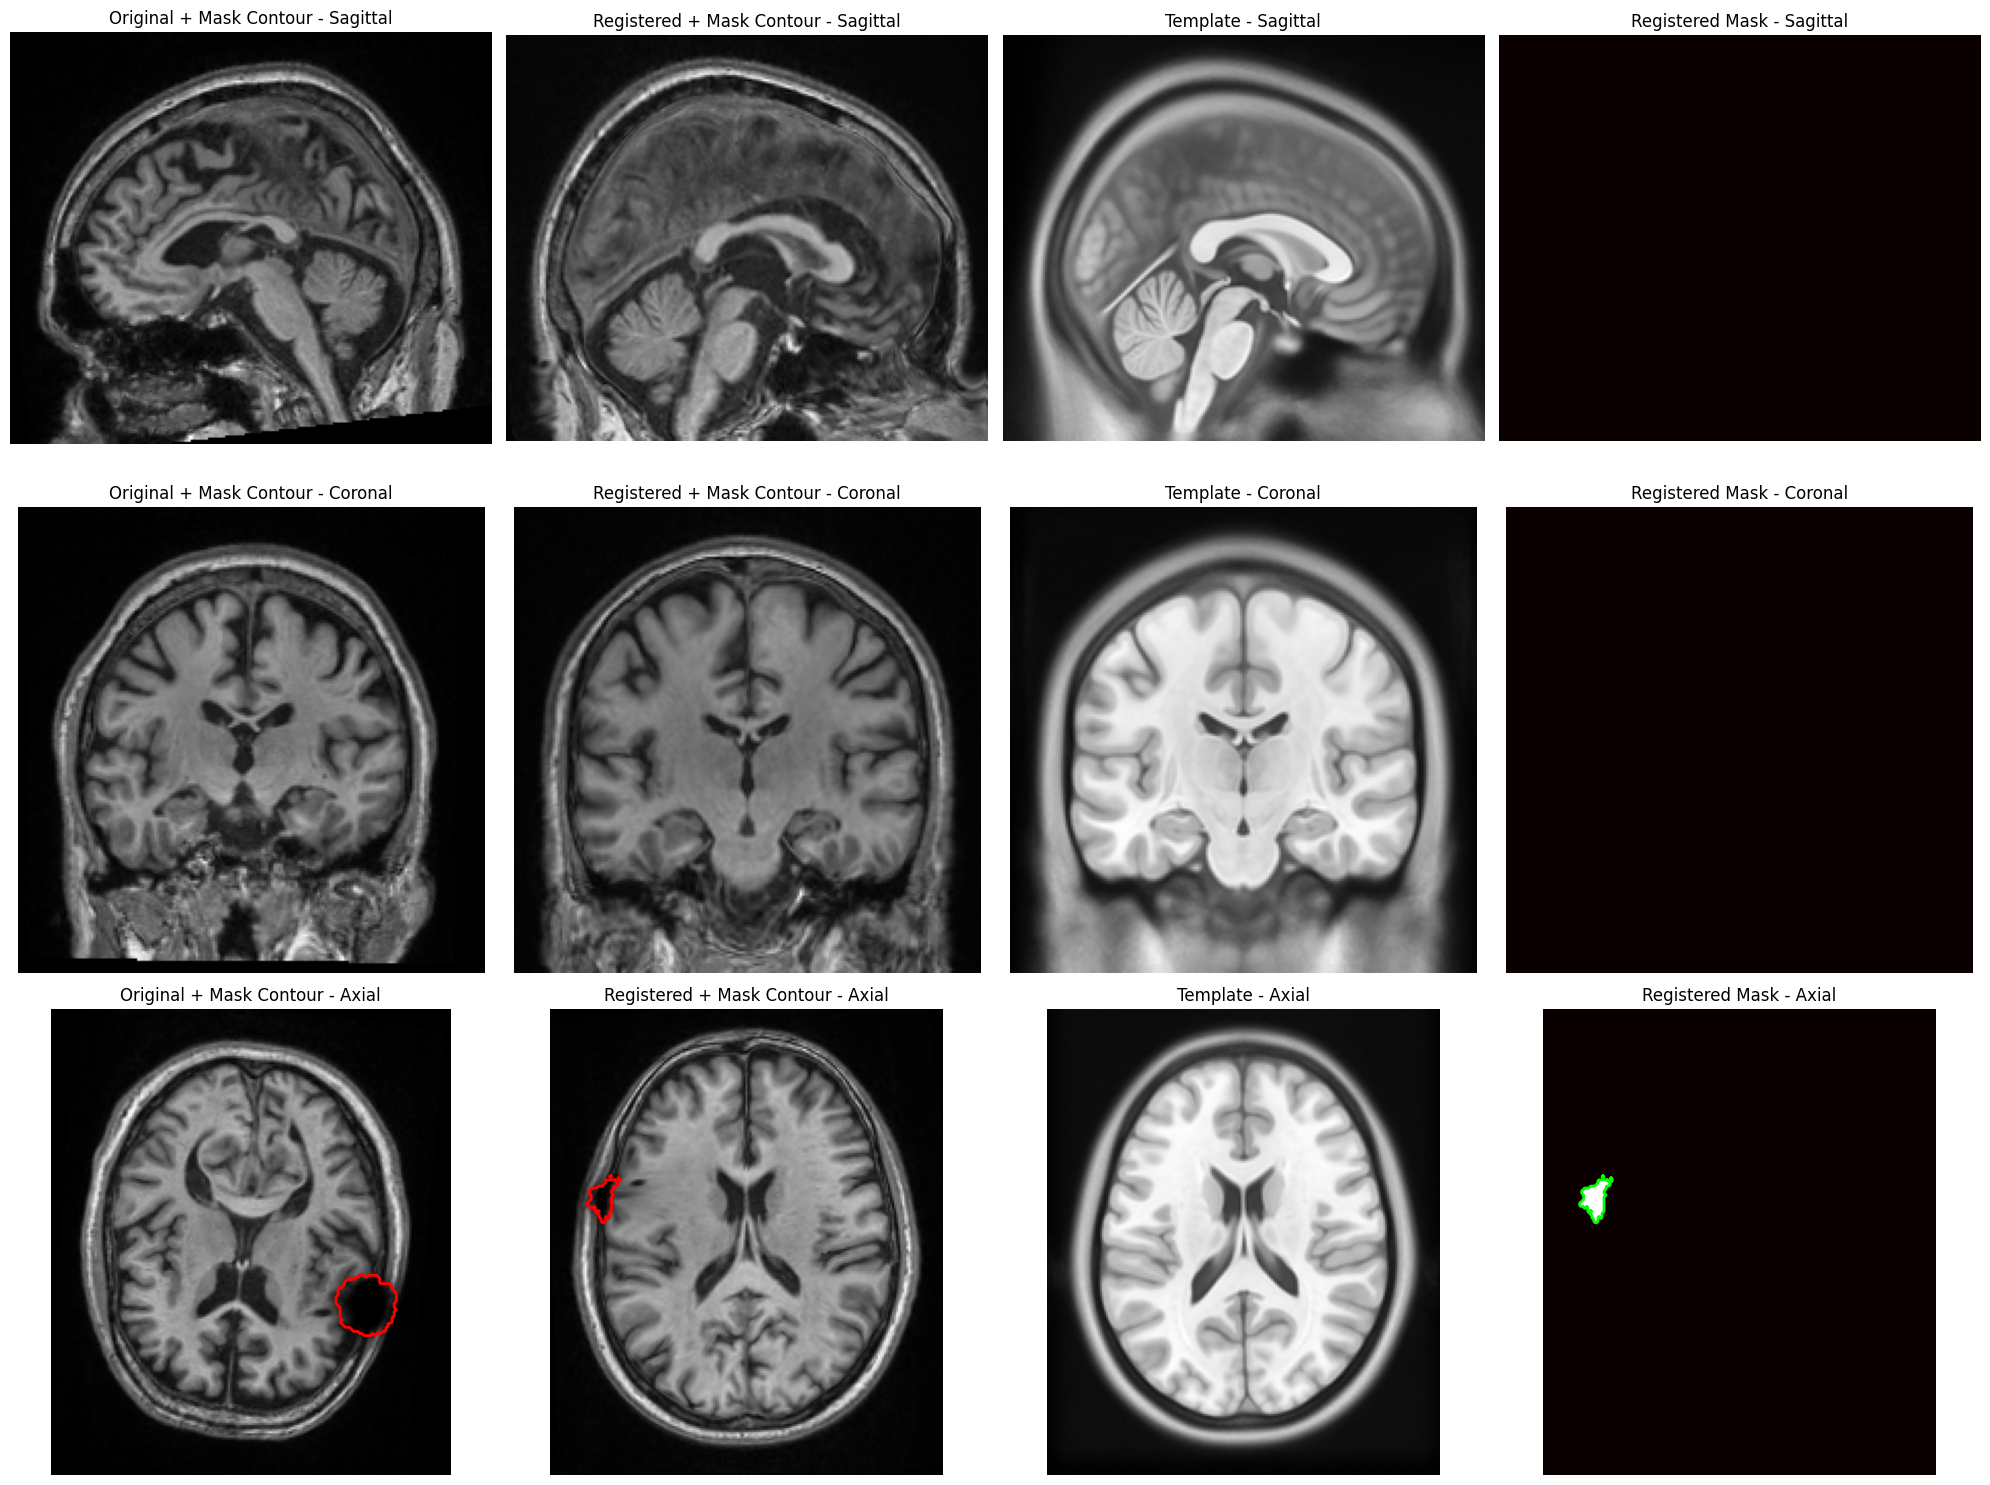

In [12]:
def visualize_registration_multiview(original, registered_image, registered_mask, template_path, original_mask):
    """
    Show registration quality with mask contour circles on both original and registered
    """
    from scipy import ndimage
    from skimage import measure
    
    template_img = ants.image_read(template_path)

    # Convert to numpy
    if hasattr(original, 'numpy'):
        original = original.numpy()
    if hasattr(registered_image, 'numpy'):
        registered_image = registered_image.numpy()
    if hasattr(registered_mask, 'numpy'):
        registered_mask = registered_mask.numpy()
    if hasattr(original_mask, 'numpy'):
        original_mask = original_mask.numpy()
    
    template = template_img.numpy()
    
    print(f"Original shape: {original.shape}")
    print(f"Registered shape: {registered_image.shape}")
    print(f"Original mask non-zero: {np.sum(original_mask > 0)}")
    print(f"Registered mask non-zero: {np.sum(registered_mask > 0)}")
    
    # Handle 4D if needed
    if len(original.shape) == 4:
        original = original[:, :, :, 0]
        original_mask = original_mask[:, :, :, 0]
        registered_image = registered_image[:, :, :, 0]
        registered_mask = registered_mask[:, :, :, 0]
        template = template[:, :, :, 0]
    
    # Get middle slices
    mid_sag = original.shape[0] // 2
    mid_cor = original.shape[1] // 2
    mid_axi = original.shape[2] // 2
    
    # For registered images
    reg_mid_sag = registered_image.shape[0] // 2
    reg_mid_cor = registered_image.shape[1] // 2
    reg_mid_axi = registered_image.shape[2] // 2
    
    fig, axes = plt.subplots(3, 4, figsize=(20, 15))
    
    # ============ SAGITTAL VIEW ============
    # Original + contour
    axes[0, 0].imshow(original[mid_sag, :, :].T, cmap='gray', origin='lower')
    orig_mask_slice = original_mask[mid_sag, :, :].T
    if np.any(orig_mask_slice > 0):
        contours = measure.find_contours(orig_mask_slice, 0.5)
        for contour in contours:
            axes[0, 0].plot(contour[:, 1], contour[:, 0], 'r-', linewidth=2)
    axes[0, 0].set_title('Original + Mask Contour - Sagittal')
    axes[0, 0].axis('off')
    
    # Registered + contour
    axes[0, 1].imshow(registered_image[reg_mid_sag, :, :].T, cmap='gray', origin='lower')
    reg_mask_slice = registered_mask[reg_mid_sag, :, :].T
    if np.any(reg_mask_slice > 0):
        contours = measure.find_contours(reg_mask_slice, 0.5)
        for contour in contours:
            axes[0, 1].plot(contour[:, 1], contour[:, 0], 'r-', linewidth=2)
    axes[0, 1].set_title('Registered + Mask Contour - Sagittal')
    axes[0, 1].axis('off')
    
    # Template
    axes[0, 2].imshow(template[reg_mid_sag, :, :].T, cmap='gray', origin='lower')
    axes[0, 2].set_title('Template - Sagittal')
    axes[0, 2].axis('off')
    
    # Registered mask only with contour
    axes[0, 3].imshow(reg_mask_slice, cmap='hot', origin='lower')
    if np.any(reg_mask_slice > 0):
        contours = measure.find_contours(reg_mask_slice, 0.5)
        for contour in contours:
            axes[0, 3].plot(contour[:, 1], contour[:, 0], 'lime', linewidth=2)
    axes[0, 3].set_title('Registered Mask - Sagittal')
    axes[0, 3].axis('off')
    
    # ============ CORONAL VIEW ============
    # Original + contour
    axes[1, 0].imshow(original[:, mid_cor, :].T, cmap='gray', origin='lower')
    orig_mask_slice = original_mask[:, mid_cor, :].T
    if np.any(orig_mask_slice > 0):
        contours = measure.find_contours(orig_mask_slice, 0.5)
        for contour in contours:
            axes[1, 0].plot(contour[:, 1], contour[:, 0], 'r-', linewidth=2)
    axes[1, 0].set_title('Original + Mask Contour - Coronal')
    axes[1, 0].axis('off')
    
    # Registered + contour
    axes[1, 1].imshow(registered_image[:, reg_mid_cor, :].T, cmap='gray', origin='lower')
    reg_mask_slice = registered_mask[:, reg_mid_cor, :].T
    if np.any(reg_mask_slice > 0):
        contours = measure.find_contours(reg_mask_slice, 0.5)
        for contour in contours:
            axes[1, 1].plot(contour[:, 1], contour[:, 0], 'r-', linewidth=2)
    axes[1, 1].set_title('Registered + Mask Contour - Coronal')
    axes[1, 1].axis('off')
    
    # Template
    axes[1, 2].imshow(template[:, reg_mid_cor, :].T, cmap='gray', origin='lower')
    axes[1, 2].set_title('Template - Coronal')
    axes[1, 2].axis('off')
    
    # Registered mask only with contour
    axes[1, 3].imshow(reg_mask_slice, cmap='hot', origin='lower')
    if np.any(reg_mask_slice > 0):
        contours = measure.find_contours(reg_mask_slice, 0.5)
        for contour in contours:
            axes[1, 3].plot(contour[:, 1], contour[:, 0], 'lime', linewidth=2)
    axes[1, 3].set_title('Registered Mask - Coronal')
    axes[1, 3].axis('off')
    
    # ============ AXIAL VIEW ============
    # Original + contour
    axes[2, 0].imshow(original[:, :, mid_axi].T, cmap='gray', origin='lower')
    orig_mask_slice = original_mask[:, :, mid_axi].T
    if np.any(orig_mask_slice > 0):
        contours = measure.find_contours(orig_mask_slice, 0.5)
        for contour in contours:
            axes[2, 0].plot(contour[:, 1], contour[:, 0], 'r-', linewidth=2)
    axes[2, 0].set_title('Original + Mask Contour - Axial')
    axes[2, 0].axis('off')
    
    # Registered + contour
    axes[2, 1].imshow(registered_image[:, :, reg_mid_axi].T, cmap='gray', origin='lower')
    reg_mask_slice = registered_mask[:, :, reg_mid_axi].T
    if np.any(reg_mask_slice > 0):
        contours = measure.find_contours(reg_mask_slice, 0.5)
        for contour in contours:
            axes[2, 1].plot(contour[:, 1], contour[:, 0], 'r-', linewidth=2)
    axes[2, 1].set_title('Registered + Mask Contour - Axial')
    axes[2, 1].axis('off')
    
    # Template
    axes[2, 2].imshow(template[:, :, reg_mid_axi].T, cmap='gray', origin='lower')
    axes[2, 2].set_title('Template - Axial')
    axes[2, 2].axis('off')
    
    # Registered mask only with contour
    axes[2, 3].imshow(reg_mask_slice, cmap='hot', origin='lower')
    if np.any(reg_mask_slice > 0):
        contours = measure.find_contours(reg_mask_slice, 0.5)
        for contour in contours:
            axes[2, 3].plot(contour[:, 1], contour[:, 0], 'lime', linewidth=2)
    axes[2, 3].set_title('Registered Mask - Axial')
    axes[2, 3].axis('off')
    
    plt.tight_layout()
    plt.savefig('registration_multiview_contours.png', dpi=150, bbox_inches='tight')
    plt.show()

def register_and_warp(subject_path, mask_path, template_path, output_dir, registration_type):
    # Load everything
    subject = ants.image_read(subject_path)
    mask = ants.image_read(mask_path)
    template = ants.image_read(template_path)

    # CRITICAL FIX: Match mask header to subject
    # This prevents the mask from being "out" of alignment
    mask = ants.copy_image_info(subject, mask)

    # 1. Calculate the transform using the BRAIN, not the mask
    # We use the corrected image for math, but keep the original for warping
    subject_corr = ants.n4_bias_field_correction(subject)
    
    registration = ants.registration(
        fixed=template,
        moving=subject_corr,
        type_of_transform=registration_type,
        outprefix=str(output_dir / 'reg_')
    )

    # 2. Apply to the Brain Image
    reg_brain = ants.apply_transforms(
        fixed=template,
        moving=subject,
        transformlist=registration['fwdtransforms'],
        interpolator='lanczosWindowedSinc'
    )

    # 3. Apply to the Mask (using the SAME transform)
    reg_mask = ants.apply_transforms(
        fixed=template,
        moving=mask,
        transformlist=registration['fwdtransforms'],
        interpolator='nearestNeighbor' # Keep it binary!
    )

    return reg_brain, reg_mask

subject_path='data/Train/subj010/subj010_image.nii.gz'
artifact_path = 'data/Train/subj010/subj010_artifact.nii.gz'
template_path='templates/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii'
# template_path = 'data/Train/subj001/subj001_image.nii.gz'
registered_path = 'data/Train/subj001/subj001_image_registered.nii.gz'
output_dir=Path('data/Train/subj001')

mask_data, mask = load_nifti(GROUND_TRUTH_MASK)

registered_image, registered_mask = register_and_warp(
    subject_path, artifact_path, template_path, output_dir, registration_type='SyN'
)
 
visualize_registration_multiview(original_data, registered_image, registered_mask, template_path, mask_data)

In [13]:
img_data = registered_image.numpy()
artifact_data = registered_mask.numpy()

In [14]:
from ipywidgets import interact, IntSlider, Dropdown

def view_slice_multi(axis_name, slice_idx):
    """Interactive slice viewer supporting Axial, Coronal, and Sagittal views"""
    # Mapping axis names to indices
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    axis = axis_map[axis_name]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Helper to extract the slice correctly based on axis
    def get_slice(volume, idx, ax):
        if volume is None: return None
        if ax == 0: return volume[idx, :, :].T
        if ax == 1: return volume[:, idx, :].T
        if ax == 2: return volume[:, :, idx].T
        return None

    img_slice = get_slice(img_data, slice_idx, axis)

    vmin_1, vmax_99 = img_data.min(), img_data.max()
    
    # Set titles and plot
    titles = [f'MRI ({axis_name})', 'MRI + Catheter', 'MRI + Artifact']
    
    for i in range(3):
        axes[i].imshow(img_slice, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
        axes[i].axis('off')
        
    # Overlay Catheter (Cyan)
    # if catheter_data is not None:
    #     c_slice = get_slice(catheter_data, slice_idx, axis)
    #     if c_slice.max() > 0:
    #         axes[1].contour(c_slice, levels=[0.5], colors='cyan', linewidths=2)
    #         axes[1].contourf(c_slice, levels=[0.5, 1], colors='cyan', alpha=0.3)
            
    # Overlay Artifact (Red)
    if artifact_data is not None:
        a_slice = get_slice(artifact_data, slice_idx, axis)
        if a_slice.max() > 0:
            axes[2].contour(a_slice, levels=[0.5], colors='red', linewidths=2)
            axes[2].contourf(a_slice, levels=[0.5, 1], colors='red', alpha=0.3)

    for i, title in enumerate(titles):
        axes[i].set_title(f"{title} - Slice {slice_idx}", fontsize=12, fontweight='bold')
        
    plt.tight_layout()
    plt.show()

# Update slider max value dynamically based on chosen axis
def update_view(axis_name):
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    max_val = img_data.shape[axis_map[axis_name]] - 1
    
    interact(view_slice_multi, 
             axis_name=Dropdown(options=['Axial (S-I)', 'Coronal (A-P)', 'Sagittal (L-R)'], value=axis_name),
             slice_idx=IntSlider(min=0, max=max_val, step=1, value=max_val//2, continuous_update=False))

update_view('Axial (S-I)')

interactive(children=(Dropdown(description='axis_name', options=('Axial (S-I)', 'Coronal (A-P)', 'Sagittal (L-…